# EurecomGPT — Phase 2: train a tiny GPT & measure parallelism

Run this in **Google Colab** with a **GPU** runtime (Runtime -> Change runtime type -> T4 GPU). It exercises Lecture 3: CPU vectorization (SIMD), CPU threads and GPU (CUDA). The model code ships working; implementing it yourself (from `templates/`) is optional. The mandatory work is running this notebook end to end.

Run the cells **in order** — later cells reuse variables the earlier ones define (`data`, `sweep`, `cpu_s`, `GCS_URL`, ...), and the final report cell collects all of them. If you restart the runtime, start again from section 0.

**Drive cache (added).** Every expensive result (timings, thread sweep, CPU/GPU comparison, trained weights, public URL) is saved to `MyDrive/eurecomgpt-phase2-cache/`. After a disconnect, run all the cells again from the top: the ones that have already finished are loaded from Drive in a second instead of being recomputed. To force a step to run again, put its name in `RERUN` (section 0b).

## 0. Setup — clone your repo and install dependencies

Colab starts with an empty disk, so first pull in your own repository: that is where your `model.py`, `attention_numpy.py` and the helper modules live. Two packages are not preinstalled in Colab — `safetensors` (the weight format we save in) and `google-cloud-storage` (used in section 6 to publish the model).

In [1]:
# Edit the URL to YOUR repo — this is the code the rest of the notebook imports.
# Always clone from /content into the 'repo' folder, so %cd repo finds it.
# '|| true' makes re-running the cell harmless (the folder already exists).
%cd /content
!git clone https://github.com/Montini-Eurecom/EurecomGPT-Montini.git repo 2>/dev/null || true
%cd /content/repo
!git pull -q
!pip -q install safetensors google-cloud-storage
# Phase-2 modules are in a subfolder, so add it to the import path.
import sys
if 'phase-2-tiny-gpt' not in sys.path: sys.path.insert(0, 'phase-2-tiny-gpt')

/content
/content/repo


## 0b. Drive cache — survive runtime disconnects

Mount your Google Drive (a popup asks for permission) and define two helpers:

- `cached(name, compute)` — if `<name>.json` is already in the cache folder, it reads it from there; otherwise it runs `compute()`, saves the result and returns it.
- `RERUN` — the set of names to recompute even if they are already in the cache. Names used: `attention`, `sweep`, `devices`, `training`, `upload`.

**Note:** cached timings are only valid if they were measured on the same type of runtime (T4 GPU). If you change runtime, empty the folder or put the names in `RERUN`.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import json, os, shutil
CACHE = '/content/drive/MyDrive/eurecomgpt-phase2-cache'
os.makedirs(CACHE, exist_ok=True)

RERUN = set()   # e.g. {'training', 'upload'} to force those steps to run again

def cache_path(name):
    return f'{CACHE}/{name}.json'

def cached(name, compute):
    """Return the cached result for `name`, or compute it and save it to Drive."""
    p = cache_path(name)
    if name not in RERUN and os.path.exists(p):
        print(f'[cache] {name}: loaded from Drive (not recomputed)')
        with open(p) as f:
            return json.load(f)
    value = compute()
    with open(p, 'w') as f:
        json.dump(value, f, indent=2)
    print(f'[cache] {name}: computed and saved to Drive')
    return value

def invalidate(name):
    """Delete a cached result (used when something it depends on changes)."""
    if os.path.exists(cache_path(name)):
        os.remove(cache_path(name)); print(f'[cache] {name}: invalidated')

print('cache folder:', CACHE)
print('already in the cache:', sorted(os.listdir(CACHE)) or 'nothing')

Mounted at /content/drive
cache folder: /content/drive/MyDrive/eurecomgpt-phase2-cache
already in the cache: nothing


### Imports, and confirm the GPU is really attached

What each import is for:

- `attention_naive` / `attention_vectorized` — the two implementations of the *same* attention maths that section 1 times against each other.
- `CONFIG` — the model's hyperparameters (layers, heads, embedding width). Everything downstream builds the model from this one object.
- `GPT` — the transformer itself.
- `train` / `experiments` — provided helpers: batching, the training loop, sampling, the timing harnesses and the report writer.

**Check the printed device.** If it says `cpu`, the GPU runtime is not attached and section 4 will show no speedup — fix it with Runtime -> Change runtime type -> T4 GPU before going on.

In [3]:
import numpy as np, torch
from attention_numpy import attention_naive, attention_vectorized
from config import CONFIG
from model import GPT
import train, experiments

# 'cuda' only if Colab actually gave us a GPU runtime; everything else falls back to CPU.
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)

device: cuda | torch 2.14.1+cu130


## 1. Attention: naive loops vs vectorized (SIMD)

Both functions compute *identical* attention output — the only difference is how they get there. `attention_naive` walks the sequence with Python loops, one dot product at a time. `attention_vectorized` hands whole matrices to NumPy, which dispatches to a BLAS library compiled with AVX/SIMD instructions that process several floats per CPU cycle.

`T=256` is the sequence length and `d=64` the head dimension — the same shapes the real model uses, so the timing is representative.

**What to look for:** a large speedup (often 100x or more) from code that is mathematically the same. `np.show_config()` prints which BLAS NumPy is linked against — that library is where the speedup actually comes from.

In [4]:
# Same maths, timed two ways. T = sequence length, d = head dimension.
r = cached('attention', lambda: {
    't_naive': experiments.time_attention(attention_naive, T=256, d=64),
    't_vec':   experiments.time_attention(attention_vectorized, T=256, d=64),
})
t_naive, t_vec = r['t_naive'], r['t_vec']
print(f'naive      : {t_naive:.2f} ms')
print(f'vectorized : {t_vec:.2f} ms   ({t_naive / t_vec:.1f}x faster)')

# Which BLAS is NumPy using? This is what makes the vectorized version fast.
np.show_config()

[cache] attention: computed and saved to Drive
naive      : 458.47 ms
vectorized : 12.00 ms   (38.2x faster)
Build Dependencies:
  blas:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.13.8/lib/python3.13/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.13.8/lib/python3.13/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.31.188.0  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3.31.188.0
  lapack:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.13.8/lib/python3.13/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.13.8/lib/python3.13/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.31.188.0  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THRE

## 2. Load the training corpus

Everything from here on needs training data, so load it once into `data` and reuse it.

The text is TinyShakespeare (~1 MB). If your repo already contains `input.txt` it is used directly; otherwise it is downloaded. `train.encode` turns the characters into integer token ids, and the result becomes one long 1-D tensor that later cells slice batches out of.

**What to look for:** a token count around one million. A much smaller number means the download failed and later training will not converge.

In [5]:
import os, urllib.request

# Prefer a local copy if the repo has one; otherwise fetch TinyShakespeare (~1 MB).
if os.path.exists('phase-2-tiny-gpt/input.txt'):
    text = open('phase-2-tiny-gpt/input.txt', encoding='utf-8', errors='replace').read()
else:
    url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
    text = urllib.request.urlopen(url).read().decode('utf-8', 'replace')

# Encode characters -> token ids, as one long 1-D tensor to slice batches from.
data = torch.tensor(train.encode(text), dtype=torch.long)
print('corpus tokens:', len(data))

corpus tokens: 1115394


## 3. Multi-threading: sweep CPU threads (intra-op parallelism)

PyTorch splits a single CPU operation — a matrix multiply, say — across `torch.set_num_threads(n)` worker threads. This is *intra-op* parallelism: one operation, many cores, as opposed to running several operations at once.

The cell below builds a fresh model, defines one training step (fetch a batch, forward, backward), and times that step at 1, 2, 4 and 8 threads.

**What to look for:** time per step falls as threads are added, then flattens or gets *worse*. That turning point is the contention point — the moment coordination costs more than the extra parallelism buys — and explaining where it lands is what your reflection is about.

In [6]:
model = GPT(CONFIG)
print('parameters:', model.num_params())

# One training step: sample a batch, forward pass, backward pass. This is what gets timed.
def one_step():
    x, y = train.get_batch(data, CONFIG.block_size, 16, 'cpu')
    _, loss = model(x, y); loss.backward()

# Time that step at each thread count. Returns {'1': ms, '2': ms, ...}.
# threading_sweep restores the default thread count on the way out: the setting is
# global, and leaving it at 8 on a 2-vCPU machine would slow the CPU baseline in
# section 4 and overstate the GPU speed-up.
sweep = cached('sweep', lambda: experiments.threading_sweep(one_step, threads=(1, 2, 4, 8)))
print('threads -> ms:', sweep)
print('torch threads now:', torch.get_num_threads())

parameters: 4935680
[cache] sweep: computed and saved to Drive
threads -> ms: {'1': 2266.92, '2': 2835.983, '4': 2289.415, '8': 2398.374}
torch threads now: 1


In [7]:
!lscpu | grep -E "^CPU\(s\)|Thread\(s\) per core|Core\(s\) per socket|Model name"
import os; print('os.cpu_count():', os.cpu_count())

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
Thread(s) per core:                      2
Core(s) per socket:                      1
os.cpu_count(): 2


### Plot the sweep

The same numbers as a curve, because the shape is the point — you are looking for where it stops going down. **Save this plot**: the deliverables ask for it, and your reflection should refer to it.

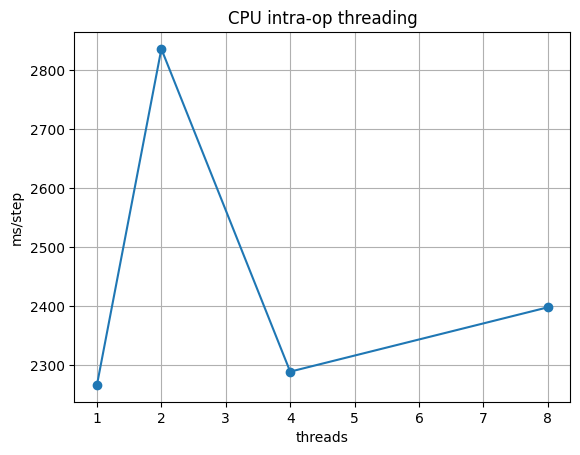

In [8]:
import matplotlib.pyplot as plt

# sweep keys are strings ('1','2',...); sort numerically so the x-axis is in order.
ts = sorted(int(k) for k in sweep)
plt.plot(ts, [sweep[str(t)] for t in ts], 'o-'); plt.xlabel('threads'); plt.ylabel('ms/step')
plt.title('CPU intra-op threading'); plt.grid(True)
plt.savefig(f'{CACHE}/threads_plot.png', dpi=120, bbox_inches='tight')   # copy on Drive
plt.show()

## 4. GPU (CUDA): the same training loop on a T4

Identical model, identical data, identical number of steps — the only thing that changes is the device. A GPU runs thousands of arithmetic units in parallel, which suits the dense matrix multiplies that dominate a transformer.

Two fresh models are built so neither run inherits the other's trained weights. `log_every=0` silences per-step logging so the timing is not distorted by printing.

**What to look for:** a large ratio — often 50x or more. If it is close to 1x, you are on a CPU runtime (check the device printed in section 0).

The CPU side of this comparison runs at PyTorch's default thread count, which section 3 restored after its sweep. Measured with the CPU still pinned to 8 threads on a 2-vCPU machine, the baseline would be fighting itself and the GPU would look better than it is.

In [9]:
# Same 100 steps on each device; two fresh models so neither reuses the other's weights.
def _devices():
    if device != 'cuda':
        print('WARNING: no GPU attached — the comparison would be meaningless. Fix the runtime type first.')
    cpu_loss, cpu_s = train.train(GPT(CONFIG), data, steps=100, device='cpu', log_every=0)
    gpu_loss, gpu_s = train.train(GPT(CONFIG), data, steps=100, device=device, log_every=0)
    return {'cpu_s': cpu_s, 'gpu_s': gpu_s, 'device': device}

r = cached('devices', _devices)
cpu_s, gpu_s = r['cpu_s'], r['gpu_s']
print(f'CPU 100 steps: {cpu_s*1000:.0f} ms  |  {r["device"]} 100 steps: {gpu_s*1000:.0f} ms',
      f'  ({cpu_s/gpu_s:.1f}x)')

[cache] devices: computed and saved to Drive
CPU 100 steps: 456327 ms  |  cuda 100 steps: 13707 ms   (33.3x)


## 5. Train the model, generate a sample, save the weights

The real training run: 2000 steps on whichever device section 0 detected. This is the model you will publish and that Phase 4 will later serve.

`train.sample` then generates 200 tokens starting from a newline, and `save_model` writes `model.safetensors`.

**What to look for:** the loss should fall well below the random-initialisation value of about 5.55 — under 3.0 is the bar. The sample will not be Shakespeare, but it should look like text: words of plausible length, line breaks, capital letters after full stops. If the loss is still near 5.5 or the sample is noise, something upstream is wrong; do not publish it.

In [10]:
from safetensors.torch import load_file

WEIGHTS_DRIVE = f'{CACHE}/model.safetensors'
model = GPT(CONFIG)

if 'training' not in RERUN and os.path.exists(cache_path('training')) and os.path.exists(WEIGHTS_DRIVE):
    # Already trained in an earlier session: reload weights and results from Drive.
    r = cached('training', lambda: None)
    model.load_state_dict(load_file(WEIGHTS_DRIVE))
    model.to(device)
    shutil.copy(WEIGHTS_DRIVE, 'model.safetensors')   # the upload cell reads this file
    final_loss, secs, sample_text = r['final_loss'], r['secs'], r['sample_text']
else:
    final_loss, secs = train.train(model, data, steps=2000, device=device, log_every=200)
    # Generate from a newline so the model starts at the beginning of a line.
    sample_text = train.sample(model, prompt='\n', max_new_tokens=200, device=device)
    # Write the weights to disk (the next section uploads this file) and copy them to Drive.
    train.save_model(model, 'model.safetensors')
    shutil.copy('model.safetensors', WEIGHTS_DRIVE)
    RERUN.add('training')   # make cached() overwrite the old record
    cached('training', lambda: {'final_loss': final_loss, 'secs': secs, 'sample_text': sample_text})
    RERUN.discard('training')
    invalidate('upload')    # new weights -> they must be uploaded again

print(f'final loss {final_loss:.3f} in {secs:.1f}s')
print('----- sample -----\n' + sample_text)

step     0  loss 5.7049
step   200  loss 2.4908
step   400  loss 2.3317
step   600  loss 2.0873
step   800  loss 1.9052
step  1000  loss 1.7956
step  1200  loss 1.7355
step  1400  loss 1.6187
step  1600  loss 1.5884
step  1800  loss 1.5055
[cache] training: computed and saved to Drive
final loss 1.486 in 267.5s
----- sample -----

Came:
If me heaven, I to was they than you sent.

Messenger:
Ado, that I whilt my body's made, amonded
I tempt my togun, incient mine will do girls,
Unworoun of thy tone brothece frighting me with fro


## 6. Upload the weights to Cloud Storage (public)

The grader cannot see your Colab session, so the model has to be published somewhere reachable — a public Cloud Storage object. Phase 4 will load the same URL to serve your model.

Colab is **not** logged into `gcloud`, so authenticate this session first. The popup asks for the Google account that owns your Phase-0 project.

In [11]:
# Authenticate only if the upload has not been done yet (or is being forced).
NEED_UPLOAD = 'upload' in RERUN or not os.path.exists(cache_path('upload'))
if NEED_UPLOAD:
    from google.colab import auth
    auth.authenticate_user()   # opens a popup to log into your Google account
else:
    print('upload already done in an earlier session: no login needed')

Now create the bucket (if it does not exist), make it publicly readable, and upload.

**Set `PROJECT` to your own Phase-0 project id before running this.** Bucket names are globally unique across all of Google Cloud, which is why the project id is used as a prefix. The model is a few MB, comfortably inside the 5 GB free tier.

**What to look for:** the printed URL should download the file when you open it in a browser. Copy it — the report needs it, and so does Phase 4.

In [12]:
PROJECT = 'eurecomgpt-montini'   # <-- your Phase-0 GCP project id
BUCKET  = f'{PROJECT}-eurecomgpt'           # bucket names are globally unique

def _upload():
    from google.cloud import storage
    client = storage.Client(project=PROJECT)

    # Reuse the bucket if a previous run (or Phase 3) already created it.
    try:
        bucket = client.get_bucket(BUCKET)
    except Exception:
        bucket = client.create_bucket(BUCKET, location='US')

    # Grant allUsers read access, so the grader can fetch the model without credentials.
    # Bucket-level IAM is used because it works with uniform bucket-level access.
    policy = bucket.get_iam_policy(requested_policy_version=3)
    policy.bindings.append({'role': 'roles/storage.objectViewer', 'members': {'allUsers'}})
    bucket.set_iam_policy(policy)

    bucket.blob('model.safetensors').upload_from_filename('model.safetensors')
    return {'gcs_url': f'https://storage.googleapis.com/{BUCKET}/model.safetensors'}

GCS_URL = cached('upload', _upload)['gcs_url']
print('public URL:', GCS_URL)

[cache] upload: computed and saved to Drive
public URL: https://storage.googleapis.com/eurecomgpt-montini-eurecomgpt/model.safetensors


## 7. Write the submission report

This collects every measurement the notebook has taken into `submission/phase2_report.json` — the attention timings from section 1, the thread sweep from section 3, the CPU/GPU comparison from section 4, the training result and sample from section 5, and the public model URL from section 6.

That is why the cells must be run in order: this one fails with a `NameError` if any earlier section was skipped, and the name it complains about tells you which.

In [13]:
report_path = experiments.write_report(
    attention={'naive_ms': t_naive, 'vectorized_ms': t_vec, 'speedup': round(t_naive/t_vec, 2)},
    threads=sweep,
    devices={'cpu_ms': round(cpu_s*1000, 1), 'gpu_ms': round(gpu_s*1000, 1)},
    training={'steps': 2000, 'final_loss': round(final_loss, 4), 'param_count': model.num_params()},
    sample_text=sample_text,
    gcs_url=GCS_URL,
)
# Copy to Drive too: from there you download it and put it in submission/ of your local repo.
shutil.copy(report_path, f'{CACHE}/phase2_report.json')
print('copy on Drive:', f'{CACHE}/phase2_report.json')

Wrote submission/phase2_report.json
copy on Drive: /content/drive/MyDrive/eurecomgpt-phase2-cache/phase2_report.json


Now **commit** `submission/phase2_report.json` and push (see TASKS.md). Your CI + the instructor grade the report + your public model.